# Live collective detection

The directional count scan and rejection subset scan use the existing likelihood functions. The top panel shows eligible scores across all searched scopes. The bottom panel shows the affected channel's observed and expected totals even where the subset exposure filter withheld a scan. The orange region is injected e-commerce interruption truth.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / 'config' / 'live_monitoring.v1.json').exists():
    root = root.parent
evidence = root / 'reports' / 'live_monitoring'
figures = evidence / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2, 'figure.dpi': 110})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(figures / (name + '.png'), dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)


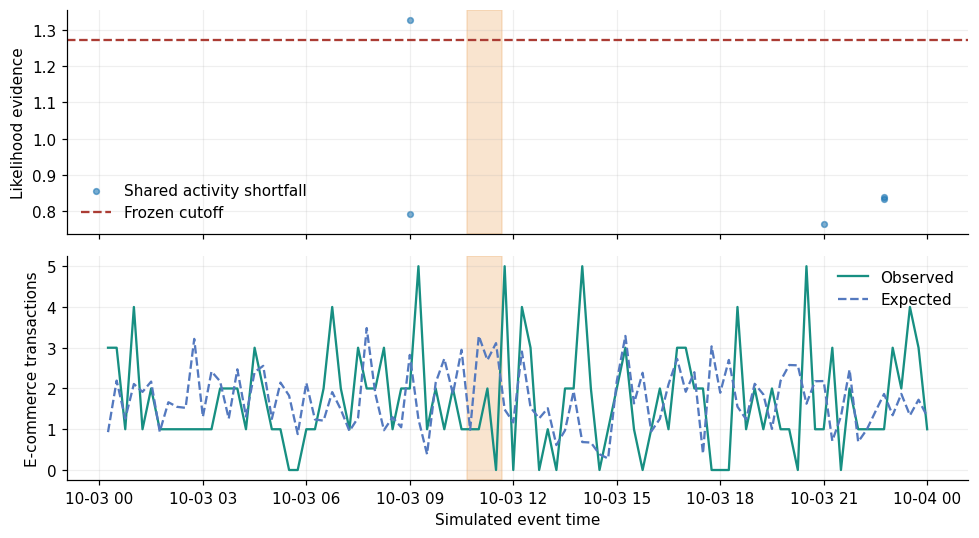

In [2]:
from src.live_monitoring.archive import Archive, BIN
from src.live_monitoring.detection import Signals
from src.live_monitoring.evaluation import locked_thresholds
a = Archive()
t = a.tape('2026-10-03','2026-10-03','collective')
s = Signals(t)
rows = []
activity = []
channel = t.ref.index['channel','ecommerce']
for i in range(t.size):
    _, scans, observed, *_ = s.tick(i)
    activity.append((observed[channel, 0], t.mean[i, channel]))
    if (i + 1) % 3 == 0:
        for row in scans:
            rows.append({**row, 'time': t.start + (i+1)*BIN})
rows = pd.DataFrame(rows, columns=['scope', 'symptom', 'score', 'merchants', 'observed', 'expected', 'time'])
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for symptom, group in rows.groupby('symptom'):
    axes[0].scatter(group.time, group.score, s=14, alpha=.6, label=symptom)
counts = np.array(activity).reshape(-1, 3, 2).sum(axis=1)
ends = [t.start + i * BIN for i in range(3, t.size + 1, 3)]
axes[1].plot(ends, counts[:, 0], label='Observed', color='#178f82')
axes[1].plot(ends, counts[:, 1], '--', label='Expected', color='#5479bf')
axes[0].axhline(locked_thresholds(a)['collective'], color='#ab3c34', linestyle='--', label='Frozen cutoff')
for ax in axes:
    ax.axvspan(t.scenario.onset, t.scenario.end, color='#eaa054', alpha=.28)
    ax.legend(frameon=False)
axes[0].set(ylabel='Likelihood evidence')
axes[1].set(xlabel='Simulated event time', ylabel='E-commerce transactions')
save(fig, 'collective_example')
